# Bushveld Gravity Continuation


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `bushveld_gravity_continuation` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：station_coordinates (1, 306, 3) float64：Station easting, northing and upward ellipsoidal height in m; last axis (easting, northing, upward)；gravity_disturbance (1, 306) float64：Real measured gravity minus WGS84 normal gravity, in mGal, matching station order；image_coordinates (1, 48, 64, 3) float64：Requested plane coordinates in m; axes batch/northing/easting/coordinate; last axis (easting, northing, upward)。恢复目标：固定高度重力扰动图，mGal。

获取模型：地下等效源的1/r核在地形站点采样并在共同平面延拓，系数不是质量。实际恢复算法：solvers.solve_coefficients/reconstruct：按列尺度化的阻尼最小二乘。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:24无延拓平面实际真值；baseline是原始标准方法结果。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：bushveld_gravity_continuation.ipynb单元6：5. Results；bushveld_gravity_continuation.ipynb单元8：Scientific comparison；bushveld_gravity_continuation.ipynb单元9有保存图；ax.set(xlabel='Easting grid index',ylabel='Northing grid index',title='Extraction numerical difference')；bushveld_gravity_continuation.ipynb单元10：Active regularization comparison；bushveld_gravity_continuation.ipynb单元11有保存图；fig.colorbar(im,ax=ax,label='mGal');ax.set_title(title)。图/比较代码位于单元9, 11（从0计数）。代码单元4个，带execution_count的4个，保存PNG输出3幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Recover the gravity-disturbance image at every point on a 3000 m ellipsoidal-height plane from 306 irregular real ground stations with differing heights. Similar equivalent-source responses make continuation ill conditioned. Exterior observations do not uniquely determine rock density or interior mass.

Save `output/reconstruction.npz`, key `reconstruction`, real float32 or float64 (1,48,64), in mGal, axes batch/northing/easting at the exact supplied image coordinates. Preserve absolute sign and scale: no crop, gain or registration fit is allowed. This is the full scaled damped equivalent-source method, not the paper's subsequent gradient-boosted algorithm; the continued field has a standard-method reference but no measured image-plane truth.


## 2. Data

These are real Bushveld survey observations from the [version-1 data archive](https://doi.org/10.5281/zenodo.6511942), original file `bushveld-gravity.csv.xz`. The source has 3877 stations. The inclusive geographic crop `27.5 <= longitude <= 29` and `-25.5 <= latitude <= -24.5` retains 306 stations in their source order. The supplied `gravity_disturbance_mgal` already has normal gravity removed and is not Bouguer-corrected. A private, fixed preprocessing step projected EPSG:4326 to WGS84 UTM35S (EPSG:32735, always_xy), subtracted horizontal offsets 600000 m and 7200000 m, and retained source geometric heights. No noise was synthesized. The requested output geometry is an endpoint-inclusive 48-by64 grid at upward height 3000 m, inset 10000 m from the station bounding box in each horizontal direction. Neither this geometry nor projection uses a hidden target. The data distributor's CC-BY-4.0 attribution and original NOAA public-domain provenance are preserved in the validation record.

All public arrays are in `data/raw_data.npz`. They use batch-first convention and contain finite float64 values. Coordinates are already projected; no geographic projection package or network access is required at solve time.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| station_coordinates | (1, 306, 3) | float64 | Station easting, northing and upward ellipsoidal height in m; last axis (easting, northing, upward) |
| gravity_disturbance | (1, 306) | float64 | Real measured gravity minus WGS84 normal gravity, in mGal, matching station order |
| image_coordinates | (1, 48, 64, 3) | float64 | Requested plane coordinates in m; axes batch/northing/easting/coordinate; last axis (easting, northing, upward) |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Survey | Bushveld gravity, version 1 | dimensionless | Redistributed ground observations |
| Geographic selection | 27.5 <= longitude <= 29; -25.5 <= latitude <= -24.5 | degree | Inclusive crop; all stations in this region retained in source order |
| Horizontal reference | WGS84 / UTM zone 35S, EPSG:32735 | m | Projection used before packaging |
| Easting offset | 600000 | m | Subtracted from projected eastings to define local coordinates |
| Northing offset | 7200000 | m | Subtracted from projected northings to define local coordinates |
| Vertical datum | WGS84 ellipsoid | m | Upward-positive geometric height, rather than height above sea level |
| Target height | 3000 | m | Ellipsoidal height of each requested image point |
| Target sampling | 48 northing rows; 64 easting columns | dimensionless | Coordinates increase along both axes |
| Target horizontal bounds | Station-coordinate minimum plus 10000; maximum minus 10000, independently for each horizontal axis | m | Endpoint-inclusive grid; exact positions in image_coordinates |
| Disturbance scale | 1 mGal = 1e-5 m/s^2 | m/s^2 | Disturbances have no Bouguer correction |
| Measurement uncertainty | Not supplied | mGal | No per-station covariance or noise calibration is available |
| Boundary assumption | Unbounded Cartesian exterior harmonic field | dimensionless | No periodic, reflecting or fixed-value lateral boundary |

The following cell actively loads the visible arrays. Hidden standard-method results are loaded only later for identified scientific comparisons; no target-derived calibration is supplied.


In [1]:
from pathlib import Path
import sys,time,json,importlib.util,subprocess
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'data/raw_data.npz').exists():
    root=root.parent
assert (root/'data/raw_data.npz').exists()
sys.path.insert(0,str(root))
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.visualization import plot_comparison
stations,data,grid=load_observations(root/'data/raw_data.npz')
print('Real stations:',len(data),'station height range (m):',stations[:,2].min(),stations[:,2].max())
print('Measured disturbance range (mGal):',data.min(),data.max())
with np.load(root/'data/raw_data.npz',allow_pickle=False) as visible:
    for key in visible.files:
        print(key,visible[key].shape,visible[key].dtype)

Real stations: 306 station height range (m): 947.8185300595775 1477.195200662288
Measured disturbance range (mGal): -42.80064780975226 46.56200753594749
station_coordinates (1, 306, 3) float64
gravity_disturbance (1, 306) float64
image_coordinates (1, 48, 64, 3) float64


## 3. Physics

Station positions $P_i$ and requested positions $G$ are in local metres (easting,northing,upward), and observations $d_i$ are gravity disturbance in mGal. The unbounded Cartesian harmonic representation is


$$
u(P)=\sum_j c_j g(P,Q_j),\qquad g(P,Q)=\|P-Q\|^{-1},\qquad d_i=u(P_i)+\epsilon_i.
$$


Q are mathematical source positions below the observations, c has units mGal m and epsilon includes survey/representation error. This 1/r basis is an exterior-field representation, not the vertical acceleration of a point mass, so coefficients must not be interpreted as mass. Away from sources its Laplacian is zero. There is no periodic image boundary or lateral fixed-value stencil. Coordinates use WGS84/UTM35S with horizontal offsets600000/7200000m; heights retain the WGS84 ellipsoid. Disturbance has normal gravity removed upstream but no Bouguer correction. The target48-by64 grid increases in northing/easting at height3000m; local Cartesian curvature and unresolved terrain remain model limitations.


## 4. Method

Let $s_j$ be the population standard deviation of column $j$ of $A$, let $S$ be their diagonal matrix, set $B=AS^{-1}$, and set $m=Sc$. Columns are scaled but never centered. With equal observational weights, minimize


$$
\Phi(m)=\|Bm-d\|_2^2+\lambda\|m\|_2^2.
$$


Here $B$ and $\lambda=0.1$ are dimensionless, while $m$ is in mGal. The direct system $(B^TB+\lambda I)m=B^Td$ and $c=S^{-1}m$ give the standard solution. Predict the target image by evaluating the same inverse-distance expansion at the public grid. The data term is a sum, not a mean. There is no iteration, initialization, intercept, or phase/alignment freedom.


## 5. Results

The saved code and outputs below belong to the existing notebook execution. This documentation review preserves those measurements and does not rerun reconstruction; “fresh” in the retained experiment narrative distinguishes the local run from the separately captured upstream result.

All fresh results below are actively reconstructed with the shipped local modules. Archived upstream arrays remain explicitly identified comparison measurements, never measured truth or a replacement for computation.


In [2]:
start=time.perf_counter()
fresh,coefficients,station_prediction=reconstruct(stations,data,grid)
reconstruction_seconds=time.perf_counter()-start
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh[None])
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as archive:
    upstream=archive['reconstruction'][0].copy()
    upstream_station=archive['station_prediction'].copy()
command=[sys.executable,str(root/'evaluation/judge.py'),'--prediction',str(root/'output/reconstruction.npz'),'--report',str(root/'output/judge_report.json')]
run=subprocess.run(command,capture_output=True,text=True)
assert run.returncode==0,run.stderr
report=json.loads((root/'output/judge_report.json').read_text())
print(json.dumps(report,indent=2))
print('Fresh reconstruction runtime (s):',reconstruction_seconds)
print('Fresh/upstream maximum absolute difference (mGal):',float(np.max(abs(fresh-upstream))))

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999999999999,
    "nrmse": 2.1818383573873326e-16
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.0002644319101659889
    }
  },
  "errors": []
}


Fresh reconstruction runtime (s): 0.032038699951954186
Fresh/upstream maximum absolute difference (mGal): 6.483702463810914e-14


### Scientific comparison

The first panel shows actual observed values at their irregular station positions and heights. The next two panels compare freshly computed and independently reproduced upstream fields on the same 3000 m plane and shared color scale. Their agreement measures extraction fidelity, rather than true geological accuracy. The last panel shows fitted values at the original station heights, where an independently meaningful observation residual can be calculated.


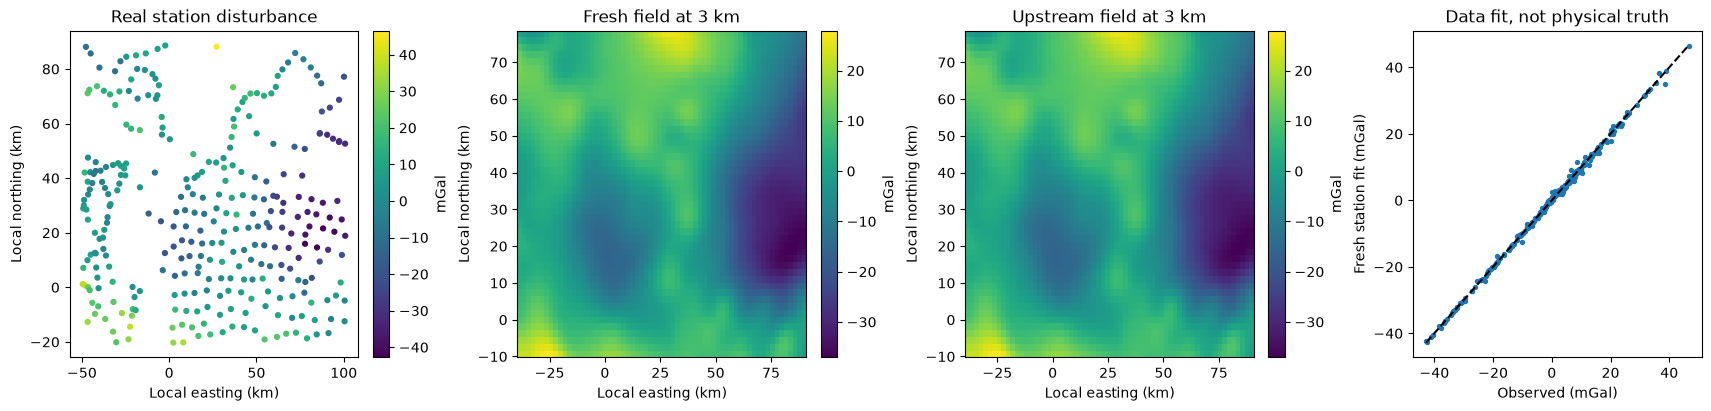

Fresh station RMSE (mGal): 0.636177032346924
Upstream station RMSE (mGal): 0.636177032346923


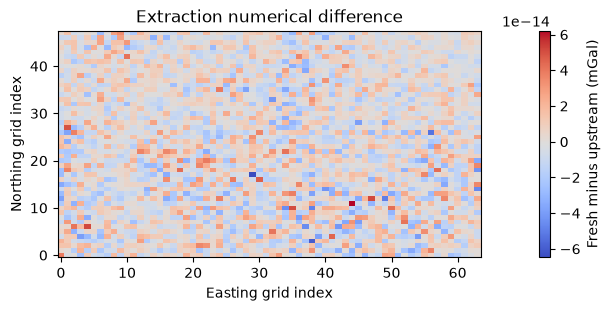

In [3]:
fig=plot_comparison(stations,data,grid,fresh,upstream,station_prediction)
plt.show()
station_rmse=float(np.sqrt(np.mean((station_prediction-data)**2)))
print('Fresh station RMSE (mGal):',station_rmse)
print('Upstream station RMSE (mGal):',float(np.sqrt(np.mean((upstream_station-data)**2))))
fig,ax=plt.subplots(figsize=(6,3),constrained_layout=True)
im=ax.imshow(fresh-upstream,origin='lower',aspect='auto',cmap='coolwarm')
fig.colorbar(im,ax=ax,label='Fresh minus upstream (mGal)')
ax.set(xlabel='Easting grid index',ylabel='Northing grid index',title='Extraction numerical difference')
plt.show()

### Active regularization comparison

A second local reconstruction uses the same real observations and depth with weaker damping (0.0001). This separately computed comparison illustrates the balance between residual reduction and coefficient magnitude. It is not the declared standard submission or a substitute for its reconstruction. A smaller station residual alone does not prove a more accurate continued field. No hidden truth is available for tuning.


[
  {
    "method": "Reproduced upstream standard",
    "station_rmse_mgal": 0.636177032346923
  },
  {
    "method": "Fresh standard lambda=0.1",
    "station_rmse_mgal": 0.636177032346924,
    "coefficient_l2_mgal_m": 2116633.8642870868
  },
  {
    "method": "Fresh weak damping lambda=0.0001",
    "station_rmse_mgal": 0.17826481071320174,
    "coefficient_l2_mgal_m": 10107171.895898078
  }
]


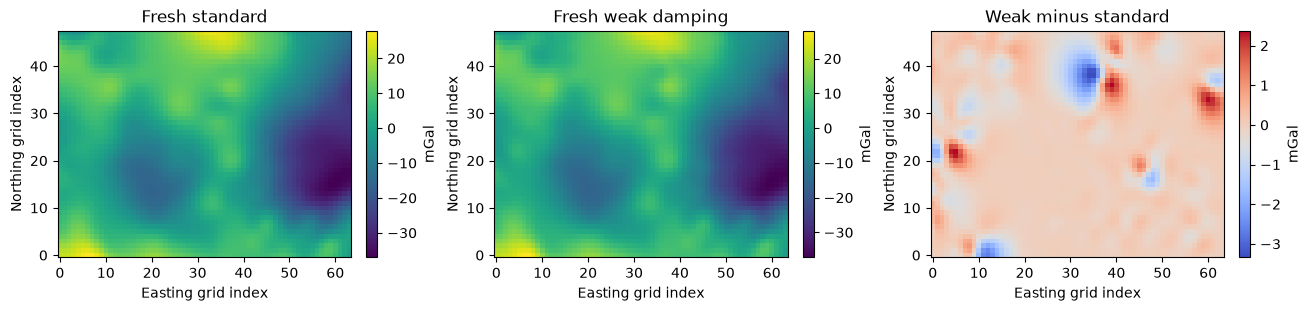

752

In [4]:
comparison_start=time.perf_counter()
weak,weak_coefficients,weak_fit=reconstruct(stations,data,grid,damping=0.0001)
weak_seconds=time.perf_counter()-comparison_start
rows=[{'method':'Reproduced upstream standard','station_rmse_mgal':float(np.sqrt(np.mean((upstream_station-data)**2)))},
      {'method':'Fresh standard lambda=0.1','station_rmse_mgal':station_rmse,'coefficient_l2_mgal_m':float(np.linalg.norm(coefficients))},
      {'method':'Fresh weak damping lambda=0.0001','station_rmse_mgal':float(np.sqrt(np.mean((weak_fit-data)**2))),'coefficient_l2_mgal_m':float(np.linalg.norm(weak_coefficients))}]
print(json.dumps(rows,indent=2))
fig,axes=plt.subplots(1,3,figsize=(13,3),constrained_layout=True)
for ax,image,title in zip(axes,[fresh,weak,weak-fresh],['Fresh standard','Fresh weak damping','Weak minus standard']):
    im=ax.imshow(image,origin='lower',aspect='auto',cmap='viridis' if 'minus' not in title else 'coolwarm')
    fig.colorbar(im,ax=ax,label='mGal');ax.set_title(title)
    ax.set_xlabel('Easting grid index');ax.set_ylabel('Northing grid index')
plt.show()
np.savez_compressed(root/'notebooks/reference_outputs/cleaned.npz',reconstruction=fresh[None],station_prediction=station_prediction,weak_reconstruction=weak[None],weak_station_prediction=weak_fit)
measurements={'reconstruction_seconds':reconstruction_seconds,'weak_comparison_seconds':weak_seconds,'judge_metrics':report['metrics'],'station_rmse_mgal':station_rmse,'maximum_absolute_upstream_difference_mgal':float(np.max(abs(fresh-upstream))),'comparisons':rows}
(root/'notebooks/reference_outputs/cleaned_measurements.json').write_text(json.dumps(measurements,indent=2,allow_nan=False),encoding='utf8')

## 6. Conclusion

The fresh extracted model reproduces the original standard-method continuation while fitting the real station observations to sub-mGal RMS. Upward continuation is an exterior-field image rather than unique mass recovery. The explicit standard and weaker-damping comparison illustrate sensitivity to regularization; numerical reference agreement is separate from uncertainty in the survey and the locally Cartesian harmonic approximation. There is no actual truth measurement on the image plane. Independent known-distance, adjoint, harmonic-Laplacian and alternative least-squares checks live under `test/` and complement this notebook's active pipeline.


The weaker-damping run tests conditioning with the same real stations and source geometry. A reduced station residual cannot establish the continued field at unmeasured height, and equivalent-source coefficients do not identify subsurface masses.
